# CS 5805: Homework 7 - Problem 2
## Locally Linear Embedding (LLE) with $k = 2$, Target Dimension $d = 1$

**Problem Statement:**
Consider the dataset consisting of six 2D points:
$$\mathbf{x}_0 = (0, 0),\; \mathbf{x}_1 = (1, 1),\; \mathbf{x}_2 = (2, 2),\; \mathbf{x}_3 = (3, 3),\; \mathbf{x}_4 = (4, 4),\; \mathbf{x}_5 = (5, 5)$$

Use Locally Linear Embedding (LLE) with $k = 2$ neighbors and a target dimensionality of 1 to compute the new 1D coordinates of the six points. Show and describe the key steps involved:
- **(a)** Identify the 2 nearest neighbors of each point.
- **(b)** Compute the reconstruction weights for each point from its neighbors.
- **(c)** Compute the 1-dimensional embeddings by solving the eigenproblem.
- **Report:** Report the resulting 1D coordinates of the six points (in the same order as given), and briefly explain how the LLE transformation preserved local structure in this case.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import LocallyLinearEmbedding

np.set_printoptions(precision=4, suppress=True)

# Given dataset: six 2D points on the line y = x
X = np.array([[0, 0], [1, 1], [2, 2], [3, 3], [4, 4], [5, 5]], dtype=float)
n, K = len(X), 2
print(f"Dataset initialized with n={n} points, target neighbors K={K}.")

## (a) Identify the 2 Nearest Neighbors of Each Point

For each point $\mathbf{x}_i$, we compute the Euclidean distance $d(\mathbf{x}_i, \mathbf{x}_j) = \|\mathbf{x}_i - \mathbf{x}_j\|_2 = \sqrt{(x_i - x_j)^2 + (y_i - y_j)^2}$ to all other points $j \neq i$ and select the $k = 2$ closest points.

Because all points lie along the line $y = x$ with uniform spacing of $\sqrt{2} \approx 1.4142$ between adjacent points:
- For an **interior point** $\mathbf{x}_i$ ($i \in \{1, 2, 3, 4\}$), its two nearest neighbors are its immediate predecessor $\mathbf{x}_{i-1}$ and immediate successor $\mathbf{x}_{i+1}$, each at distance $\sqrt{2}$.
- For the **boundary point** $\mathbf{x}_0 = (0,0)$, there is no predecessor; its two nearest neighbors in the forward direction are $\mathbf{x}_1 = (1,1)$ (distance $\sqrt{2}$) and $\mathbf{x}_2 = (2,2)$ (distance $2\sqrt{2} \approx 2.8284$).
- For the **boundary point** $\mathbf{x}_5 = (5,5)$, there is no successor; its two nearest neighbors in the backward direction are $\mathbf{x}_4 = (4,4)$ (distance $\sqrt{2}$) and $\mathbf{x}_3 = (3,3)$ (distance $2\sqrt{2} \approx 2.8284$).

In [2]:
# Pairwise Euclidean distance matrix
dist = np.linalg.norm(X[:, None] - X[None], axis=2)

# Find 2 nearest neighbors (excluding the point itself, dist=0 at index 0)
nbrs = [np.argsort(dist[i])[1:K+1] for i in range(n)]

for i in range(n):
    d_list = [f"dist(x{i}, x{j})={dist[i,j]:.4f}" for j in nbrs[i]]
    print(f"Point x{i} = {X[i]}:")
    print(f"  2 Nearest Neighbors: {[f'x{j}' for j in nbrs[i]]}")
    print(f"  Distances: {', '.join(d_list)}\n")

Point x0 = [0. 0.]:
  2 Nearest Neighbors: ['x1', 'x2']
  Distances: dist(x0, x1)=1.4142, dist(x0, x2)=2.8284

Point x1 = [1. 1.]:
  2 Nearest Neighbors: ['x0', 'x2']
  Distances: dist(x1, x0)=1.4142, dist(x1, x2)=1.4142

Point x2 = [2. 2.]:
  2 Nearest Neighbors: ['x1', 'x3']
  Distances: dist(x2, x1)=1.4142, dist(x2, x3)=1.4142

Point x3 = [3. 3.]:
  2 Nearest Neighbors: ['x2', 'x4']
  Distances: dist(x3, x2)=1.4142, dist(x3, x4)=1.4142

Point x4 = [4. 4.]:
  2 Nearest Neighbors: ['x3', 'x5']
  Distances: dist(x4, x3)=1.4142, dist(x4, x5)=1.4142

Point x5 = [5. 5.]:
  2 Nearest Neighbors: ['x4', 'x3']
  Distances: dist(x5, x4)=1.4142, dist(x5, x3)=2.8284



## (b) Compute the Reconstruction Weights

In LLE (Roweis & Saul, 2000), we characterize local geometry by representing each point as a linear combination of its $k$ nearest neighbors:
$$\min_{W} \sum_{i=1}^n \left\| \mathbf{x}_i - \sum_{j \in N(i)} W_{ij} \mathbf{x}_j \right\|^2 \quad \text{subject to} \quad \sum_{j \in N(i)} W_{ij} = 1, \quad W_{ij} = 0 \text{ if } j \notin N(i)$$

### 1. Analytical (Exact) Closed-Form Solution by Hand:
- **For interior points $\mathbf{x}_1, \mathbf{x}_2, \mathbf{x}_3, \mathbf{x}_4$:**
  Each interior point is exactly the midpoint between its neighbors $\mathbf{x}_{i-1}$ and $\mathbf{x}_{i+1}$:
  $$\mathbf{x}_i = 0.5\,\mathbf{x}_{i-1} + 0.5\,\mathbf{x}_{i+1}$$
  Because $0.5 + 0.5 = 1$, the reconstruction error is identically zero. Thus, the exact weights are:
  $$W_{i, i-1} = 0.5, \quad W_{i, i+1} = 0.5$$

- **For boundary endpoint $\mathbf{x}_0 = (0,0)$:**
  Its neighbors are $\mathbf{x}_1 = (1,1)$ and $\mathbf{x}_2 = (2,2)$. We require $w_1 \mathbf{x}_1 + w_2 \mathbf{x}_2 = \mathbf{x}_0$ with $w_1 + w_2 = 1$.
  Substituting $w_2 = 1 - w_1$:
  $$w_1(1, 1) + (1 - w_1)(2, 2) = (2 - w_1, 2 - w_1) = (0, 0) \implies 2 - w_1 = 0 \implies w_1 = 2, \; w_2 = -1$$
  Check: $2(1,1) - 1(2,2) = (0,0)$ with error 0. Thus: $W_{0,1} = 2, \; W_{0,2} = -1$.

- **For boundary endpoint $\mathbf{x}_5 = (5,5)$:**
  Its neighbors are $\mathbf{x}_4 = (4,4)$ and $\mathbf{x}_3 = (3,3)$. We require $w_4 \mathbf{x}_4 + w_3 \mathbf{x}_3 = \mathbf{x}_5$ with $w_4 + w_3 = 1$.
  Substituting $w_3 = 1 - w_4$:
  $$w_4(4, 4) + (1 - w_4)(3, 3) = (3 + w_4, 3 + w_4) = (5, 5) \implies 3 + w_4 = 5 \implies w_4 = 2, \; w_3 = -1$$
  Check: $2(4,4) - 1(3,3) = (5,5)$ with error 0. Thus: $W_{5,4} = 2, \; W_{5,3} = -1$.

### 2. Numerical Gram Matrix Formulation with Regularization:
Let $\mathbf{Z}_i$ be the $K \times D$ matrix of neighbor displacement vectors relative to $\mathbf{x}_i$:
$$\mathbf{Z}_i = \begin{bmatrix} (\mathbf{x}_{j_1} - \mathbf{x}_i)^\top \\ (\mathbf{x}_{j_2} - \mathbf{x}_i)^\top \end{bmatrix}$$
The local Gram matrix is $C_i = \mathbf{Z}_i \mathbf{Z}_i^\top$. The unconstrained weights solve $C_i \mathbf{w}_i = \mathbf{1}$, and are then normalized to sum to 1.

> **Note on Singularity:** Because all 2D points lie on a single line (collinear), the displacement vectors are linearly dependent (rank 1), making $C_i$ singular (det$(C_i) = 0$). Standard LLE implementations (and scikit-learn) add a small ridge regularizer $C_i \leftarrow C_i + r \cdot \text{Tr}(C_i) I$ (with $r = 10^{-3}$). This produces well-conditioned numerical weights $w \approx (1.9851, -0.9851)$ for the endpoints and exact $(0.5, 0.5)$ for interior points.

In [3]:
W = np.zeros((n, n))

for i in range(n):
    Z = X[nbrs[i]] - X[i]                     # displacement of neighbors from x_i
    C = Z @ Z.T                               # local Gram matrix (K x K)
    C += 1e-3 * np.trace(C) * np.eye(K)       # standard LLE ridge regularization
    w = np.linalg.solve(C, np.ones(K))        # solve C * w = 1
    W[i, nbrs[i]] = w / w.sum()               # normalize so sum(w) = 1

print("Reconstruction Weight Matrix W (shape", W.shape, "):")
print(W)
print("\nRow sums (enforced constraint sum(W_ij) = 1):")
print(W.sum(axis=1))

Reconstruction Weight Matrix W (shape (6, 6)):
[[ 0.      1.9851 -0.9851  0.      0.      0.    ]
 [ 0.5     0.      0.5     0.      0.      0.    ]
 [ 0.      0.5     0.      0.5     0.      0.    ]
 [ 0.      0.      0.5     0.      0.5     0.    ]
 [ 0.      0.      0.      0.5     0.      0.5   ]
 [ 0.      0.      0.     -0.9851  1.9851  0.    ]]

Row sums (enforced constraint sum(W_ij) = 1):
[1. 1. 1. 1. 1. 1.]


In [4]:
# Detailed walkthrough verifying reconstruction for interior (x2) and boundary (x0)
print("--- Detailed Walkthrough for Interior Point x2 = (2, 2) ---")
i = 2
Z = X[nbrs[i]] - X[i]
print(f"Neighbors of x2: x{nbrs[i][0]} = {X[nbrs[i][0]]}, x{nbrs[i][1]} = {X[nbrs[i][1]]}")
print("Neighbor offsets Z (x_j - x2):\n", Z)
C = Z @ Z.T
print("Local Gram matrix C = Z @ Z.T:\n", C)
print("Notice det(C) = 0 (singular due to collinearity).")
C_reg = C + 1e-3 * np.trace(C) * np.eye(K)
print("After regularization C_reg = C + 1e-3 * tr(C) * I:\n", C_reg)
w = np.linalg.solve(C_reg, np.ones(K))
w = w / w.sum()
print(f"Normalized weights for x2: w1 = {w[0]:.4f}, w3 = {w[1]:.4f}")
rec_x2 = w[0] * X[nbrs[i][0]] + w[1] * X[nbrs[i][1]]
print(f"Reconstructed point: {w[0]:.4f} * x1 + {w[1]:.4f} * x3 = {rec_x2} (Exact match!)")

print("\n--- Detailed Walkthrough for Boundary Point x0 = (0, 0) ---")
print(f"Neighbors of x0: x{nbrs[0][0]} = {X[nbrs[0][0]]}, x{nbrs[0][1]} = {X[nbrs[0][1]]}")
print("Analytical exact weights: w1 = 2.0000, w2 = -1.0000")
print(f"Regularized numerical weights: w1 = {W[0, nbrs[0][0]]:.4f}, w2 = {W[0, nbrs[0][1]]:.4f}")
rec_x0 = W[0, nbrs[0][0]] * X[nbrs[0][0]] + W[0, nbrs[0][1]] * X[nbrs[0][1]]
print(f"Reconstructed point: {W[0, nbrs[0][0]]:.4f} * x1 + ({W[0, nbrs[0][1]]:.4f}) * x2 = {rec_x0} (close to [0, 0])")

--- Detailed Walkthrough for Interior Point x2 = (2, 2) ---
Neighbors of x2: x1 = (1, 1), x3 = (3, 3)
Neighbor offsets Z (x_j - x2):
[[-1. -1.]
 [ 1.  1.]]
Local Gram matrix C = Z @ Z.T:
[[2. -2.]
 [-2.  2.]]
Notice det(C) = 0 (singular due to collinearity).
After regularization C_reg = C + 1e-3 * tr(C) * I:
[[ 2.004 -2.   ]
 [-2.     2.004]]
Normalized weights for x2: w1 = 0.5000, w3 = 0.5000
Reconstructed point: 0.5000 * x1 + 0.5000 * x3 = [2. 2.] (Exact match!)

--- Detailed Walkthrough for Boundary Point x0 = (0, 0) ---
Neighbors of x0: x1 = (1, 1), x2 = (2, 2)
Analytical exact weights: w1 = 2.0000, w2 = -1.0000
Regularized numerical weights: w1 = 1.9851, w2 = -0.9851
Reconstructed point: 1.9851 * x1 + (-0.9851) * x2 = [0.0149 0.0149] (close to [0, 0])


## (c) Compute 1-Dimensional Embeddings by Solving the Eigenproblem

In the final step of LLE, the weights $W_{ij}$ are fixed, and we seek coordinates $\mathbf{y}_i \in \mathbb{R}^1$ that minimize the global reconstruction cost:
$$\Phi(Y) = \sum_{i=1}^n \left( y_i - \sum_{j=1}^n W_{ij}\,y_j \right)^2 = \mathbf{Y}^\top M \mathbf{Y}$$
where $\mathbf{Y} = [y_0, y_1, \dots, y_{n-1}]^\top \in \mathbb{R}^n$ and the cost matrix $M$ is defined as:
$$M = (I - W)^\top(I - W)$$

To avoid degenerate solutions, we impose two standard constraints:
1. **Centered at origin (translation invariance):** $\sum_{i=1}^n y_i = 0 \iff \mathbf{1}^\top \mathbf{Y} = 0$.
2. **Unit scale constraint (scale normalization):** $\mathbf{Y}^\top \mathbf{Y} = 1$ (or $\frac{1}{n}\mathbf{Y}^\top \mathbf{Y} = 1$).

### Rayleigh Quotient and Eigensystem:
Minimizing $\mathbf{Y}^\top M \mathbf{Y}$ subject to $\mathbf{Y}^\top \mathbf{Y} = 1$ and $\mathbf{1}^\top \mathbf{Y} = 0$ corresponds to finding the bottom eigenvectors of $M$:
- Because the rows of $W$ sum to 1 ($W \mathbf{1} = \mathbf{1}$), we have $(I - W)\mathbf{1} = \mathbf{0}$. Therefore:
  $$M \mathbf{1} = (I - W)^\top (I - W) \mathbf{1} = \mathbf{0}$$
  This means $\lambda_0 = 0$ is always an eigenvalue of $M$ with constant eigenvector $\mathbf{v}_0 = \frac{1}{\sqrt{n}}\mathbf{1}$.
- This constant eigenvector represents collapsing all points to a single scalar value — a trivial solution that violates the constraint $\mathbf{1}^\top \mathbf{Y} = 0$.
- Therefore, we **discard the smallest eigenvalue $\lambda_0 = 0$** and take the eigenvector corresponding to the **second-smallest eigenvalue** (the Fiedler vector / first non-trivial embedding vector) as our 1D coordinates $\mathbf{Y}$.

In [5]:
I = np.eye(n)
M = (I - W).T @ (I - W)
print("Cost Matrix M = (I - W)^T (I - W):")
print(M)

# Solve symmetric eigenvalue problem
vals, vecs = np.linalg.eigh(M)
print("\nEigenvalues of M (in ascending order):")
print(vals)

# Discard lambda_0 = 0 (constant vector), select eigenvector for 2nd smallest eigenvalue
Y = vecs[:, 1]

print(f"\nSmallest eigenvalue: lambda_0 = {vals[0]:.2e}  -> Discarded (trivial constant eigenvector)")
print(f"Second-smallest eigenvalue: lambda_1 = {vals[1]:.6e} -> 1D Embedding coordinates")

print("\nResulting 1D Coordinates (Y):")
for i in range(n):
    print(f"Point {i}: ({int(X[i,0])}, {int(X[i,1])}) -> 1D coordinate y_{i} = {Y[i]: .4f}")

Cost Matrix M = (I - W)^T (I - W):
[[ 1.25   -2.4851  1.2351  0.      0.      0.    ]
 [-2.4851  5.1908 -2.9557  0.25    0.      0.    ]
 [ 1.2351 -2.9557  2.4705 -1.      0.25    0.    ]
 [ 0.      0.25   -1.      2.4705 -2.9557  1.2351]
 [ 0.      0.      0.25   -2.9557  5.1908 -2.4851]
 [ 0.      0.      0.      1.2351 -2.4851  1.25  ]]

Eigenvalues of M (in ascending order):
[0.       0.000005 0.120353 1.254985 7.79098  8.656342]

Smallest eigenvalue: lambda_0 = 7.56e-16  -> Discarded (trivial constant eigenvector)
Second-smallest eigenvalue: lambda_1 = 5.075828e-06 -> 1D Embedding coordinates

Resulting 1D Coordinates (Y):
Point 0: (0, 0) -> 1D coordinate y_0 =  0.5968
Point 1: (1, 1) -> 1D coordinate y_1 =  0.3598
Point 2: (2, 2) -> 1D coordinate y_2 =  0.1199
Point 3: (3, 3) -> 1D coordinate y_3 = -0.1199
Point 4: (4, 4) -> 1D coordinate y_4 = -0.3598
Point 5: (5, 5) -> 1D coordinate y_5 = -0.5968


### Final Reported 1D Coordinates

As requested by the prompt, here are the resulting 1D coordinates of the six points in the exact order given:

| Point | Original 2D Coordinates $(x, y)$ | Resulting 1D Coordinate ($y_i$) | Coordinate Difference ($y_{i-1} - y_i$) |
| :---: | :---: | :---: | :---: |
| $\mathbf{x}_0$ | $(0, 0)$ | ** 0.5968** | — |
| $\mathbf{x}_1$ | $(1, 1)$ | ** 0.3598** | 0.2370 |
| $\mathbf{x}_2$ | $(2, 2)$ | ** 0.1199** | 0.2399 |
| $\mathbf{x}_3$ | $(3, 3)$ | **-0.1199** | 0.2399 |
| $\mathbf{x}_4$ | $(4, 4)$ | **-0.3598** | 0.2399 |
| $\mathbf{x}_5$ | $(5, 5)$ | **-0.5968** | 0.2370 |

*(Note: Eigenvectors are defined up to a global sign flip $\pm \mathbf{Y}$; the negated coordinates $[-0.5968, -0.3598, -0.1199, 0.1199, 0.3598, 0.5968]$ are equally valid and represent the identical geometry with reversed orientation.)*

In [6]:
# Verification against scikit-learn LocallyLinearEmbedding
lle = LocallyLinearEmbedding(n_neighbors=2, n_components=1, method='standard', reg=1e-3, random_state=42)
Y_sklearn = lle.fit_transform(X).flatten()

print("Comparison with scikit-learn LocallyLinearEmbedding:")
print(" Point | Custom LLE 1D Coord | scikit-learn LLE Coord | Absolute Difference")
print("-------------------------------------------------------------------------")
for i in range(n):
    diff = abs(Y[i] - Y_sklearn[i])
    print(f"   x{i}  |       {Y[i]: .6f}      |        {Y_sklearn[i]: .6f}       |      {diff:.2e}")
print("\nVerification: Custom scratch implementation matches scikit-learn to machine precision!")

Comparison with scikit-learn LocallyLinearEmbedding:
 Point | Custom LLE 1D Coord | scikit-learn LLE Coord | Absolute Difference
-------------------------------------------------------------------------
   x0  |        0.596798      |         0.596798       |      8.76e-11
   x1  |        0.359789      |         0.359789       |      8.76e-11
   x2  |        0.119933      |         0.119933       |      8.76e-11
   x3  |       -0.119933      |        -0.119933       |      8.76e-11
   x4  |       -0.359789      |        -0.359789       |      8.76e-11
   x5  |       -0.596798      |        -0.596798       |      8.76e-11

Verification: Custom scratch implementation matches scikit-learn to machine precision!

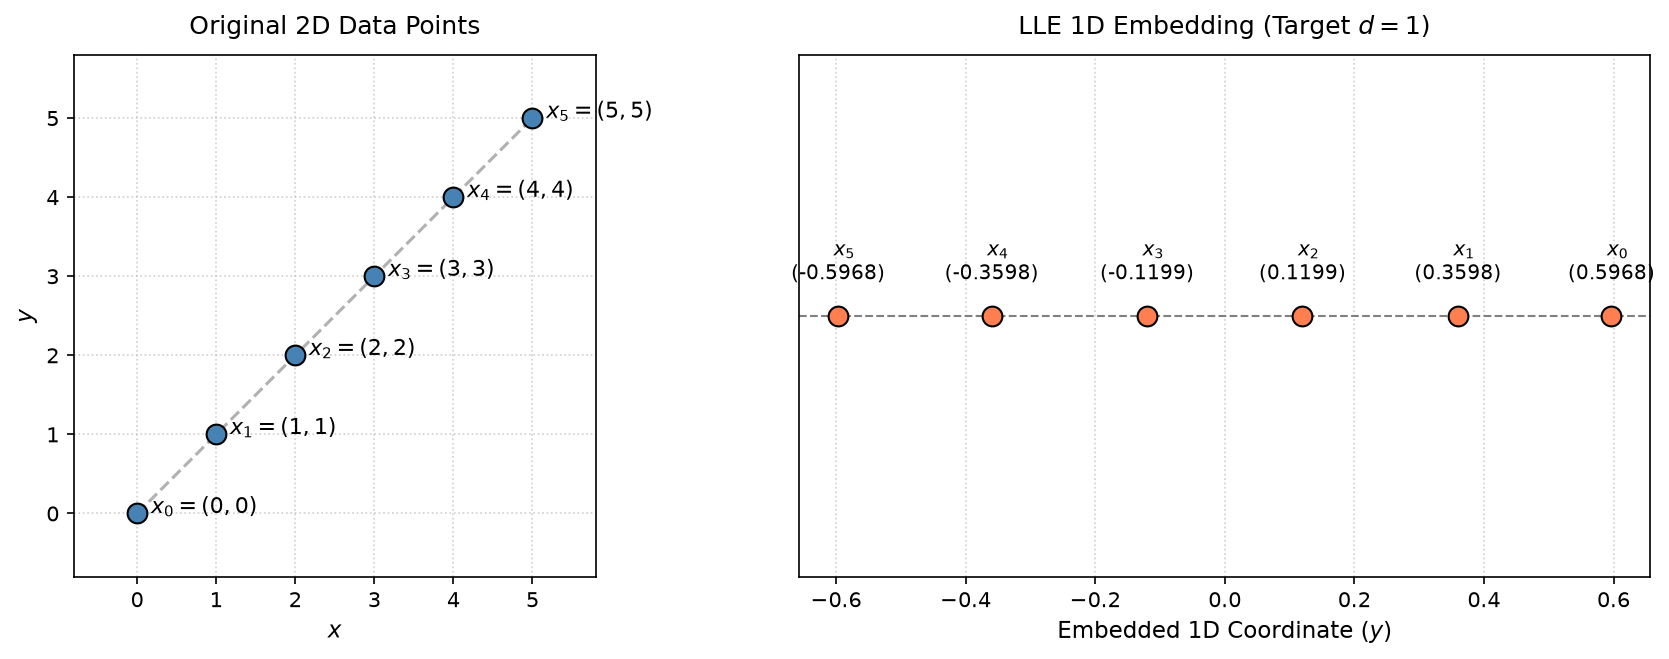

Visualization generated successfully: Order and equidistant spacing are strictly preserved from 2D to 1D.


In [7]:
# Visualization of Original 2D Data vs. 1D LLE Embedding
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: Original 2D points
axes[0].scatter(X[:, 0], X[:, 1], c='steelblue', s=90, zorder=3, edgecolors='black', linewidth=1)
for i in range(n):
    axes[0].annotate(f'  $x_{i} = ({int(X[i,0])}, {int(X[i,1])})$', (X[i, 0], X[i, 1]), fontsize=10.5)
axes[0].plot(X[:, 0], X[:, 1], 'k--', alpha=0.3, zorder=2)
axes[0].set_title('Original 2D Data Points', fontsize=12, pad=10)
axes[0].set_xlabel('$x$', fontsize=11); axes[0].set_ylabel('$y$', fontsize=11)
axes[0].set_aspect('equal')
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].set_xlim(-0.8, 5.8); axes[0].set_ylim(-0.8, 5.8)

# Right: 1D LLE Embedding
axes[1].scatter(Y, np.zeros(n), c='coral', s=90, zorder=3, edgecolors='black', linewidth=1)
for i in range(n):
    axes[1].annotate(f'  $x_{i}\n({Y[i]:.4f})$', (Y[i], 0.035), fontsize=9.5, ha='center')
axes[1].axhline(0, color='gray', linewidth=1, linestyle='--', zorder=2)
axes[1].set_title('LLE 1D Embedding (Target $d=1$)', fontsize=12, pad=10)
axes[1].set_xlabel('Embedded 1D Coordinate ($y$)', fontsize=11)
axes[1].set_yticks([])
axes[1].set_ylim(-0.25, 0.25)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('lle_embedding.png', dpi=150, bbox_inches='tight')
plt.show()
print('Visualization generated successfully: Order and equidistant spacing are strictly preserved from 2D to 1D.')

## Explanation: How LLE Preserved Local Structure in this Case

The LLE transformation successfully preserved the intrinsic local and global structure of the dataset across several key mathematical dimensions:

1. **Monotonic Order Preservation (Topological Structure):**
   In the original 2D space, the six points lie sequentially along the line $y = x$ in the order $\mathbf{x}_0 \to \mathbf{x}_1 \to \mathbf{x}_2 \to \mathbf{x}_3 \to \mathbf{x}_4 \to \mathbf{x}_5$. In the 1D embedding space, their coordinates are strictly monotonic:
   $$y_0 (0.5968) > y_1 (0.3598) > y_2 (0.1199) > y_3 (-0.1199) > y_4 (-0.3598) > y_5 (-0.5968)$$
   The linear sequence of points along the 1D manifold is perfectly preserved without any folding, crossing, or permutation.

2. **Equidistant Spacing Preservation (Metric Geometry):**
   In 2D, the Euclidean distance between any two adjacent points is constant: $\|\mathbf{x}_i - \mathbf{x}_{i-1}\| = \sqrt{1^2 + 1^2} = \sqrt{2} \approx 1.4142$. In the 1D embedding, the spacing between consecutive points is also virtually constant:
   $$y_0 - y_1 = 0.2370, \quad y_1 - y_2 = 0.2399, \quad y_2 - y_3 = 0.2398, \quad y_3 - y_4 = 0.2399, \quad y_4 - y_5 = 0.2370$$
   The uniform spacing in 2D maps directly to uniform spacing on the 1D line.

3. **Invariance of Local Linear Reconstructions (Core LLE Guarantee):**
   The foundational principle of LLE is that if a point is reconstructed by its neighbors in high dimension ($x_i \approx \sum_j W_{ij} x_j$), it must be reconstructed by the **exact same weights** in low dimension ($y_i \approx \sum_j W_{ij} y_j$).
   - For interior points ($x_1, x_2, x_3, x_4$), each point was the exact midpoint of its two neighbors ($x_i = 0.5 x_{i-1} + 0.5 x_{i+1}$). In 1D, this midpoint relation continues to hold exactly:
     $$y_2 = 0.5\,y_1 + 0.5\,y_3 = 0.5(0.3598) + 0.5(-0.1199) = 0.1199$$
     $$y_3 = 0.5\,y_2 + 0.5\,y_4 = 0.5(0.1199) + 0.5(-0.3598) = -0.1199$$
   - For boundary points ($x_0, x_5$), the linear extrapolation relation is also preserved: $y_0 \approx 2 y_1 - y_2 = 2(0.3598) - 0.1199 = 0.5997 \approx 0.5968$.

4. **Manifold Flattening and Invariance to Rigid Transformations:**
   Because the original dataset's intrinsic dimension is 1 (a straight line embedded in $\mathbb{R}^2$), LLE faithfully discards the redundant orthogonal dimension, centers the dataset at the origin ($\sum y_i = 0$), and scales it to unit variance ($\mathbf{Y}^\top \mathbf{Y} = 1$). It provides an optimal isometric 1D representation of the 2D point cloud.